In [52]:
import numpy as np 
from subprocess import check_output
import numpy as np
import laspy as lp
import matplotlib.pyplot as plt
from stl import mesh
import sys
import ezdxf
from os.path import normpath, exists
import centerline.spline as spline
import centerline.simplify as simplify 
from centerline.centerline import Centerliner, Unzigzag, writeBinPath, writeDXFPath, runModule, readBinPath
from tests.utils import find_neighbours_with_knn, return_rings

# loop over all test cases, extract centreline and plot it.

In [53]:
basenames = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable",
             "straight_cylinder_L8_R1_stochastic",
             "sinuous_D5_r_1",
             "extra_sinuous_D5_r_1", 
             "Riesengang_subset"]

             #"vers_chez_le_brandt"]


basenames = ["Archamps", "Lauiloch"]

In [55]:
rings = [] # store for plotting. 
meshes = [] # store for plotting. 

for c, basename in enumerate(basenames):

    CONDUIT_NAME = basename
    MODULE = "voxelize"
    MODULE_PATH = normpath(f"./centerline/{MODULE}.exe")
    CONDUIT_PATH = normpath(f"./tests/meshes/{CONDUIT_NAME}.stl")
    OUTPUT_PATH = normpath(f"./tests/voxsets/{CONDUIT_NAME}.vxl")
    DELTA = 200
    ADJACENT_TRIANGLES_PATH = f"./tests/meshes/{basename}_adjacent_triangles.txt"


    # run the voxelizer module. 
    check_output(f"{MODULE_PATH} {DELTA} {CONDUIT_PATH} {OUTPUT_PATH}")

    # instantiate a Centerliner class using the output voxel set and delta.
    c = Centerliner(OUTPUT_PATH, DELTA)


    c.addEdges()

    # to look at the grid and clearance
    # c.writeEdges(f"{thedir}/edges.xyz")
    keep = True
    
    meshdata = mesh.Mesh.from_file(CONDUIT_PATH)

    meshes.append(meshdata.centroids[::20])

    if exists(ADJACENT_TRIANGLES_PATH) and keep:
        adjacent_triangles = np.loadtxt(ADJACENT_TRIANGLES_PATH).astype(int)
    else:
        adjacent_triangles = find_neighbours_with_knn(meshdata)
        np.savetxt(ADJACENT_TRIANGLES_PATH,adjacent_triangles, fmt="%.1d")

        
    out = return_rings(meshdata, adjacent_triangles)
    rings.append(out)

    source1 = c.findNearestNode(out["P1"]*1000)
    target1 = c.findNearestNode(out["P2"]*1000)


    p = c.computeCenterline(source1, target1)

    # writeDXFPath(f"{thedir}/rawpath.dxf", p)

    u = Unzigzag(p, c.G.nodes, c.delta)
    u.addEdges()
    p = u.shortestPath(source1, target1)

    p1 =[np.array(x) for x in p]

    coords = np.array(p1)/1000
    
    # save to file.
    np.savetxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt", coords, fmt= "%.3e")

    thedir = "./test1/"
    # polygonal path
    writeDXFPath(f"{thedir}/centerline.dxf", p1)
    print(p1)
    # simplified polygonal path
    p2 = simplify.douglasPeucker(DELTA, p1)
    writeDXFPath(f"{thedir}/centerline-simplified.dxf", p2)

    coords = np.array(p2)/1000
    # save to file.
    np.savetxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerline-simplified.txt", coords, fmt= "%.3e")


    sys.stderr.write(f"Polyline has {len(p1)} vertices\n")
    sys.stderr.write(f"Simplified polyline has {len(p2)} vertices\n")

    # now fit cubic B-splines to p1 and p2
    writeBinPath(f"{thedir}/path.bin", p1)
    writeBinPath(f"{thedir}/path-simplified.bin", p2)

    runModule("./centerline/bspliner", [str(len(p1) / 3), f"{thedir}/path.bin", f"{thedir}/bspline.bin"])
    runModule("./centerline/bspliner", [str(len(p2) / 3), f"{thedir}/path.bin", f"{thedir}/bspline1.bin"])
    runModule(
        "./centerline/bspliner",
        [
            str(len(p2) / 3),
            f"{thedir}/path-simplified.bin",
            f"{thedir}/bspline-simplified.bin",
        ],
    )

    cps = readBinPath(f"{thedir}/bspline.bin")
    s1 = spline.bspline(cps)
    s2 = spline.subdivideBeziers(s1, 100)

    ps = [bezier[0] for bezier in s2]
    ps.append(s2[-1][-1])
    writeDXFPath(f"{thedir}/centerspline-fit.dxf", ps, ezdxf.colors.RED)

    if len(p2) > 2:

        # create B-spline directly from vertices of simplified path
        s3 = spline.bspline(p2)
        s4 = spline.subdivideBeziers(s3, 100)

        ps = [bezier[0] for bezier in s4]
        ps.append(s4[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-direct.dxf", ps, ezdxf.colors.GREEN)

        coords = np.array(ps)/1000
        # save to file.
        np.savetxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt", coords, fmt= "%.3e")


        cps = readBinPath(f"{thedir}/bspline-simplified.bin")
        s5 = spline.bspline(cps)
        s6 = spline.subdivideBeziers(s5, 100)

        ps = [bezier[0] for bezier in s6]
        ps.append(s6[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-fit-simplified.dxf", ps, ezdxf.colors.YELLOW)

        cps = readBinPath(f"{thedir}/bspline1.bin")
        s7 = spline.bspline(cps)
        s8 = spline.subdivideBeziers(s7, 100)

        ps = [bezier[0] for bezier in s8]
        ps.append(s8[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-fit1.dxf", ps, ezdxf.colors.WHITE)
    else:
        print("simplified polyline has fewer than 2 vertices. Impossible to simplify further.")
        s4 = spline.subdivideBeziers(s2, 100)

        ps = [bezier[0] for bezier in s4]
        ps.append(s4[-1][-1])
        writeDXFPath(f"{thedir}/centerspline-direct.dxf", ps, ezdxf.colors.GREEN)
        
        coords = np.array(ps)/1000
        # save to file.
        np.savetxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt", coords, fmt= "%.3e")


Read 'tests\voxsets\Archamps.vxl': 286,277 vertices and 30,266 grid points,
Added edges in 22.4 sec.


found ring 1 with 660 points.
found ring 2 with 421 points.


Computed maximum spanning tree for clearance in 2.0 sec.
Computed path in maximum spanning tree in 0.5 sec.


Added edges in 0.5 sec.
Computed shortest path in 0.1 sec.
[array([ 56800,  97200, 107000]), array([ 57000,  97200, 107000]), array([ 57200,  97200, 106800]), array([ 57400,  97200, 106600]), array([ 57600,  97200, 106600]), array([ 57800,  97200, 106600]), array([ 58000,  97200, 106600]), array([ 58200,  97200, 106600]), array([ 58400,  97200, 106600]), array([ 58600,  97200, 106400]), array([ 58800,  97200, 106400]), array([ 59000,  97200, 106400]), array([ 59200,  97200, 106200]), array([ 59400,  97200, 106200]), array([ 59600,  97200, 106200]), array([ 59800,  97200, 106200]), array([ 60000,  97200, 106200]), array([ 60200,  97200, 106200]), array([ 60400,  97200, 106200]), array([ 60600,  97200, 106000]), array([ 60800,  97200, 106000]), array([ 61000,  97200, 106000]), array([ 61200,  97200, 106000]), array([ 61400,  97200, 106000]), array([ 61600,  97200, 106000]), array([ 61800,  97200, 106000]), array([ 62000,  97200, 106000]), array([ 62200,  97200, 106000]), array([ 62400,  

Polyline has 208 vertices
Simplified polyline has 28 vertices
Read 'tests\voxsets\Lauiloch.vxl': 384,604 vertices and 28,061 grid points,
Added edges in 29.3 sec.


knn search complete and neighbouring triangles found in 510.0628s (768930 triangle neighbour sets.)
found ring 1 with 190 points.
found ring 2 with 188 points.


Computed maximum spanning tree for clearance in 2.7 sec.
Computed path in maximum spanning tree in 0.7 sec.


Added edges in 2.0 sec.
Computed shortest path in 0.3 sec.
[array([-47200, -11800,  38800]), array([-47200, -11600,  38800]), array([-47200, -11400,  38800]), array([-47200, -11200,  38800]), array([-47200, -11000,  38800]), array([-47200, -10800,  38800]), array([-47400, -10600,  39000]), array([-47600, -10400,  39200]), array([-47800, -10200,  39400]), array([-47800, -10000,  39600]), array([-47800,  -9800,  39600]), array([-47800,  -9600,  39600]), array([-47800,  -9400,  39600]), array([-48000,  -9200,  39800]), array([-48000,  -9000,  39800]), array([-48200,  -8800,  40000]), array([-48200,  -8600,  40000]), array([-48400,  -8400,  40000]), array([-48600,  -8200,  40200]), array([-48800,  -8000,  40200]), array([-49000,  -7800,  40400]), array([-49200,  -7600,  40600]), array([-49400,  -7400,  40600]), array([-49600,  -7200,  40800]), array([-49800,  -7000,  41000]), array([-50000,  -7000,  41000]), array([-50200,  -6800,  41000]), array([-50400,  -6600,  41000]), array([-50600,  

Polyline has 273 vertices
Simplified polyline has 48 vertices


In [ ]:
def plot_centrelines(basename_list,ids, out_fp, figsize =(8,6)):
    arrow_props = dict(zorder=100, scale=0.6, width= 0.01, scale_units= "x", alpha = 0.5)    

    fig = plt.figure(figsize = figsize)


    for c, (theid,  basename) in enumerate(zip(ids, basename_list)):
    
        CONDUIT_NAME = basename
        DELTA = 200

        meshdata = meshes[theid]
        ring = rings[theid]

        centreline = np.loadtxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt")
        centrespline = np.loadtxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt")
        
        ax = fig.add_subplot(3, len(basename_list), c+1)
        ax.scatter(*meshdata[::10, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*ring["P1"][[0,1]] ,*ring["nP1"][[0,1]],color = "C0", **arrow_props)
        ax.quiver(*ring["P2"][[0,1]] ,*ring["nP2"][[0,1]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,1]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [0,1]].T, "-o", markersize=1, color = "firebrick")

        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")


        ax = fig.add_subplot(3, len(basename_list), len(basename_list)+c+1)

        ax.scatter(*meshdata[::10, [0,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [0,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [0,2]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*ring["P1"][[0,2]] ,*ring["nP1"][[0,2]],color = "C0", **arrow_props)
        ax.quiver(*ring["P2"][[0,2]] ,*ring["nP2"][[0,2]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,2]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [0,2]].T, "-o", markersize=1, color = "firebrick")

        ax.set_xlabel('X')
        ax.set_ylabel('Z')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")

        ax = fig.add_subplot(3, len(basename_list), 2*len(basename_list)+c+1)

        ax.scatter(*meshdata[::10, [1,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*ring["ring1"][:, [1,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*ring["ring2"][:, [1,2]].T, c="C1", s = 2, label = "ring 2")
        ax.plot(*centreline[:, [1,2]].T, "-o", markersize=1, color = "k")
        ax.plot(*centrespline[:, [1,2]].T, "-o", markersize=1, color = "firebrick")

        ax.set_xlabel('X')
        ax.set_ylabel('Z')
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
        ax.set_aspect("equal")
        #ax.legend()
    
    plt.tight_layout()
    plt.savefig(out_fp, dpi = 300)
    plt.show()


In [29]:
basenames_simple = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable"]

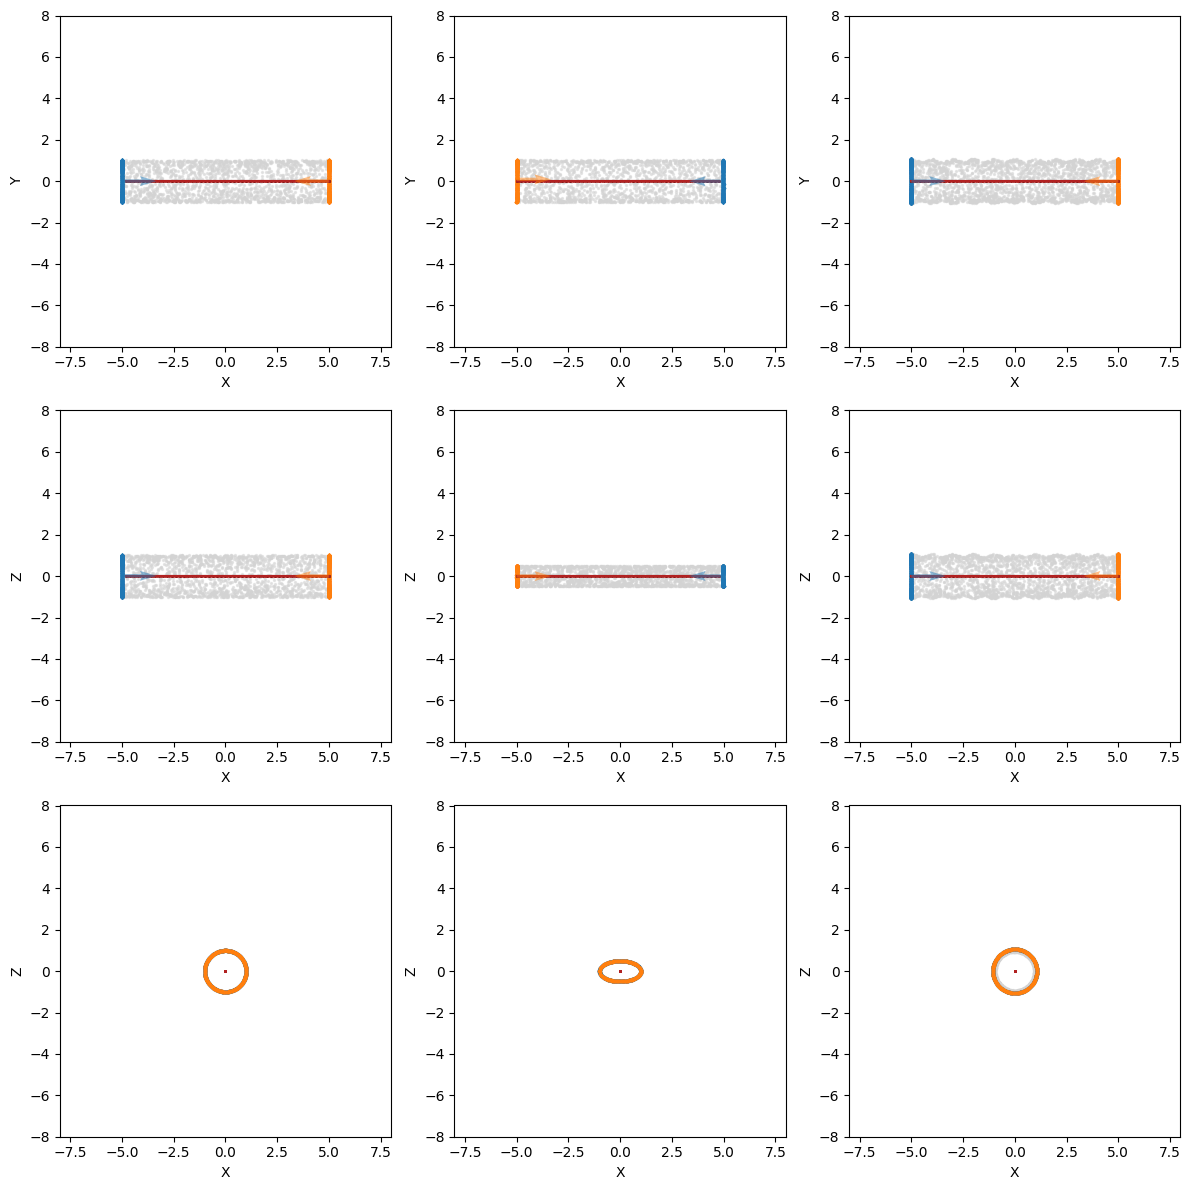

In [30]:
plot_centrelines(basenames_simple,[0,1,2], "./tests/outputs/finding_inlet_outlet_rings_and_centrelines_MST_simple.png", figsize=(12,12))

In [31]:
basenames_complex = ["straight_cylinder_L8_R1_stochastic","sinuous_D5_r_1","extra_sinuous_D5_r_1"]

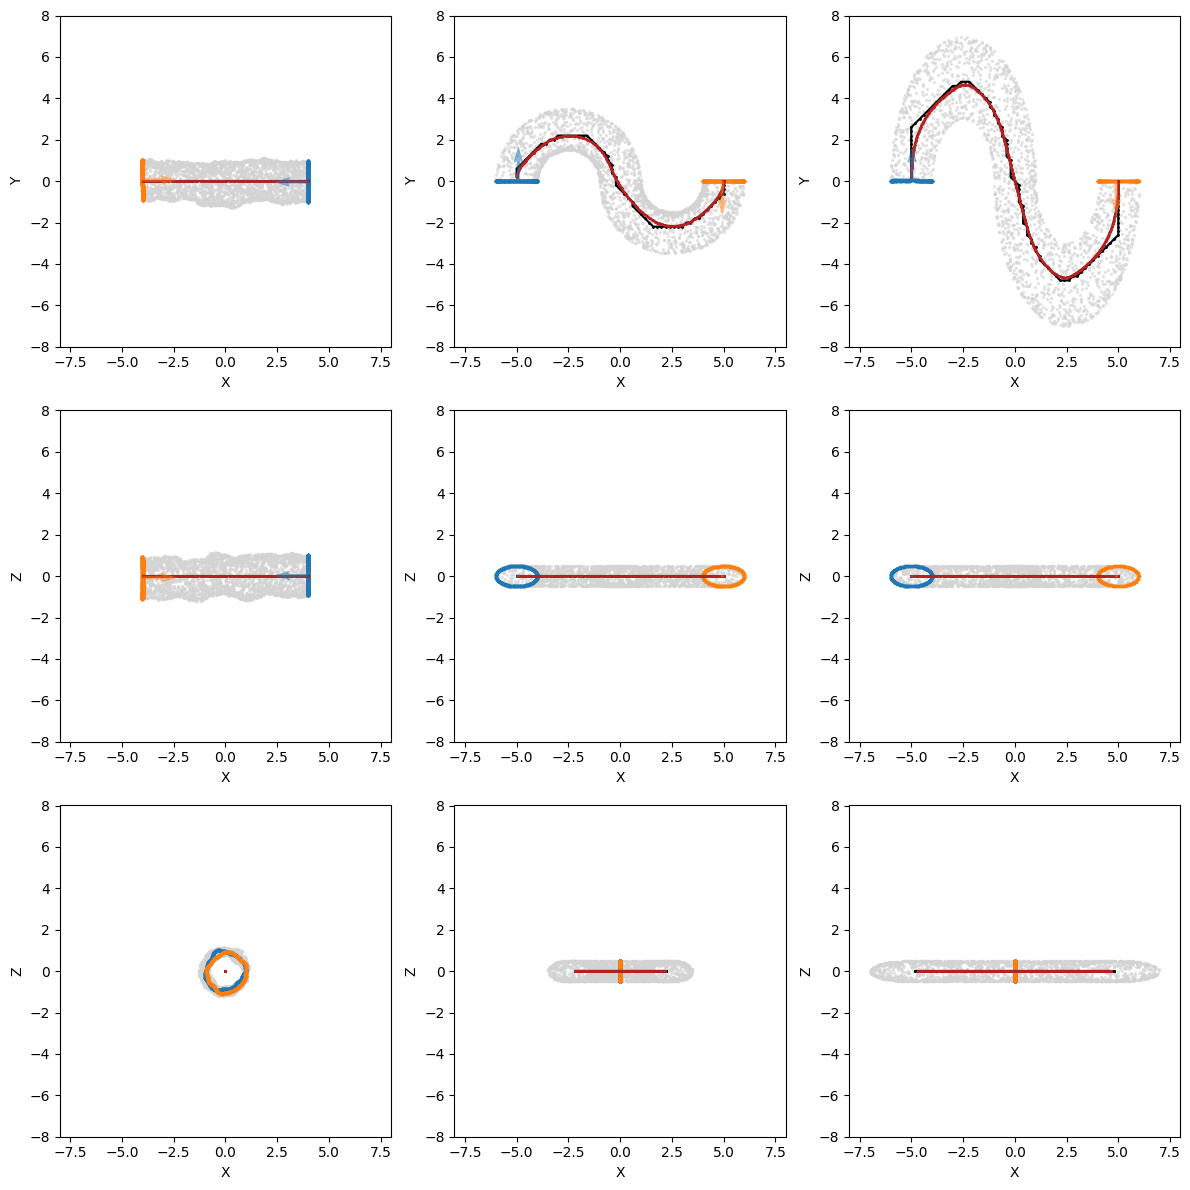

In [32]:
plot_centrelines(basenames_complex,[3,4,5], "./tests/outputs/finding_inlet_outlet_rings_and_centrelines_MST_complex.png", figsize=(12,12))

In [57]:
basenames_cave = ["Archamps","Lauiloch","Motiers"]

In [43]:
def plot_a_centreline(basename,id,  out_fp, figsize = (6,6), loc = True):

    arrow_props = dict(zorder=100, scale=0.6, width= 0.01, scale_units= "x", alpha = 0.5)    

    fig = plt.figure(figsize = figsize)


    
    CONDUIT_NAME = basename
    DELTA = 200

    meshdata = meshes[id]
    ring = rings[id]

    centreline = np.loadtxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_raw_centreline.txt")
    centrespline = np.loadtxt(f"./tests/centrelines/MST_{CONDUIT_NAME}_{DELTA}_centerspline-direct.txt")
    
    ax = fig.add_subplot(3, 1, 1)
    ax.scatter(*meshdata[::10, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
    ax.quiver(*ring["P1"][[0,1]] ,*ring["nP1"][[0,1]],color = "C0", **arrow_props)
    ax.quiver(*ring["P2"][[0,1]] ,*ring["nP2"][[0,1]],color = "C1", **arrow_props)
    ax.plot(*centreline[:, [0,1]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [0,1]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")


    ax = fig.add_subplot(3, 1, 2)

    ax.scatter(*meshdata[::10, [0,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [0,2]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [0,2]].T, c="C1", s = 2, label = "ring 2")
    ax.quiver(*ring["P1"][[0,2]] ,*ring["nP1"][[0,2]],color = "C0", **arrow_props)
    ax.quiver(*ring["P2"][[0,2]] ,*ring["nP2"][[0,2]],color = "C1", **arrow_props)
    ax.plot(*centreline[:, [0,2]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [0,2]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")

    ax = fig.add_subplot(3, 1, 3)

    ax.scatter(*meshdata[::10, [1,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*ring["ring1"][:, [1,2]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*ring["ring2"][:, [1,2]].T, c="C1", s = 2, label = "ring 2")
    ax.plot(*centreline[:, [1,2]].T, "-o", markersize=1, color = "k")
    ax.plot(*centrespline[:, [1,2]].T, "-o", markersize=1, color = "firebrick")

    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    if loc != False:
        ax.set_xlim(-8,8)
        ax.set_ylim(-8,8)
    ax.set_aspect("equal")
    #ax.legend()

    plt.tight_layout()
    plt.savefig(out_fp, dpi = 300)
    plt.show()


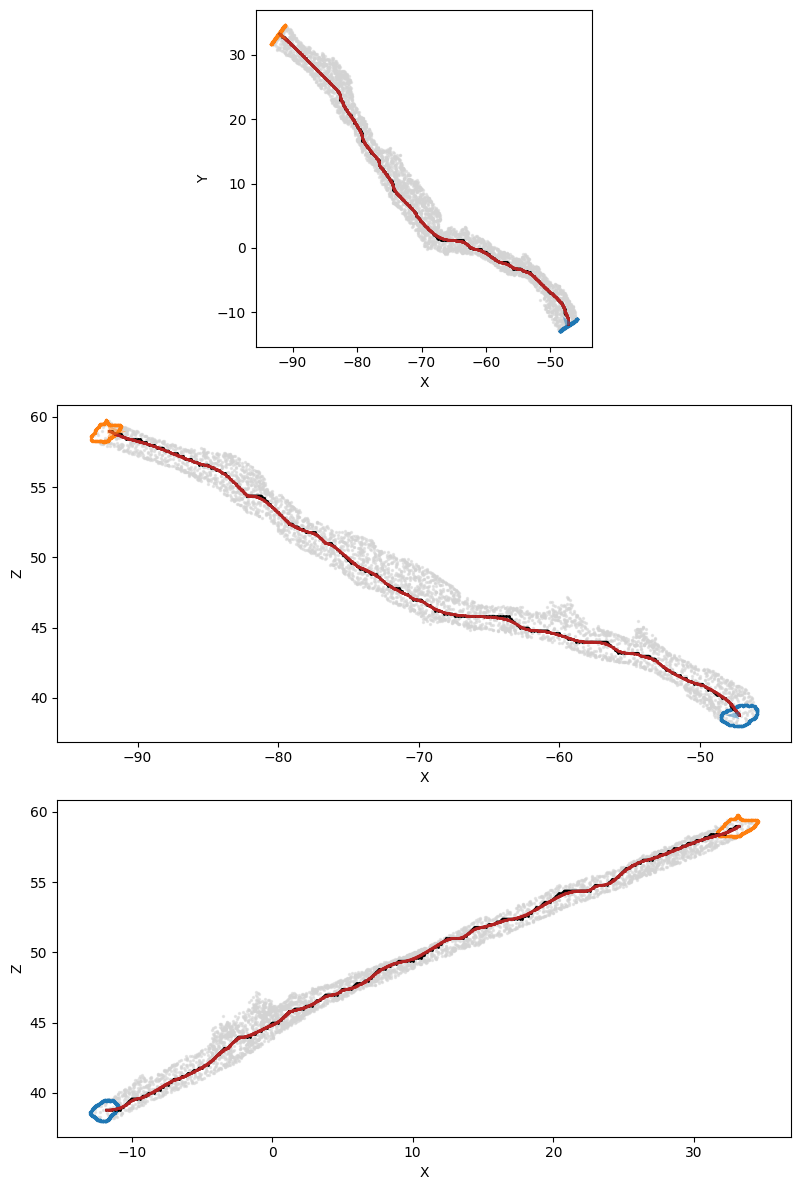

In [56]:
ID = 1

plot_a_centreline(basenames[ID], ID, 
                  f"./tests/outputs/finding_inlet_outlet_rings_and_centrelines_MST_{ID}.png",
                   figsize=(12,12), 
                   loc = False)